# 06 · 用已保存的人工眨眼标注检查 PTP 阈值

**研究范围：伪迹目标只考虑眨眼。**非有限值、不完整窗口、滤波启动期属于数据可用性检查，和眨眼检出分开统计；不新增肌电、心搏等来源判定，不删除所谓“坏通道”。

你确认：保存的 `MANUAL_bad_span` 实际标的是眨眼，并且每个浏览窗口只标了几个，**还有很多眨眼没有标**。因此这里只把已有区间视为眨眼正例，标注外一律未知。本 notebook 不改原始标注或正式阈值。

结论先看：现有 150/250/350 µV 上限均漏掉全部可评估的已标眨眼 epoch。更低阈值能提高已标样本覆盖，但目前无法判断误删率，所以不能直接确定新阈值。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/causal_pilot.json').exists())
OUT=ROOT/'outputs/blink_validation'
STEM='F_05_SE001_CBCol_Train02'
BASE=ROOT/'outputs/causal_pilot'/STEM
comparison=pd.read_csv(OUT/'threshold_blink_comparison.csv')
intervals=pd.read_csv(OUT/'manual_interval_detection.csv')
events=pd.read_csv(OUT/'epoch_blink_overlap.csv')
record=json.loads((BASE/'processing_record.json').read_text())
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
display(pd.Series(json.loads((OUT/'analysis_record.json').read_text()),name='analysis provenance').to_frame())

,analysis provenance
annotation_source,outputs\artifact_qc\continuous_manual_qc\manua...
semantic_source,User states saved bad spans are blinks; origin...
n_annotations,14
reviewed_coverage,User confirms sparse examples in each viewing ...
label_usage,none in detection
thresholds_changed,False
training_only,True
interval_overlap,"half-open integer sample ranges, ceil annotati..."
scope,blink artifact evaluation; existing data-integ...
frontal_channels,"[EEG_F3, EEG_Fz, EEG_F4]"


## 1. 标注是什么，能评估什么？

找到 F_05_SE001_CBCol_Train02 的 14 段人工标注。保存格式是**时间段**，不是某个 EEG 通道永久损坏。保留原来的 `MANUAL_bad_span` 名称，用本次用户确认说明它们是眨眼，避免重写标注历史。

CSV 时间段与独立 FIF 已核对一致。下面的表保留每段起止时间，便于回到 notebook 04 复核。

能计算：已标眨眼涉及的 epoch 有多少被阈值检出。不能计算：误删率、精确率、所有真实眨眼的召回率。原因是没有经过完整检查的阴性区间，而且你挑选的明显眨眼可能不代表全部眨眼。

In [2]:
display(intervals[['manual_id','start_sec','end_sec','duration_sec','type','overlap_epochs','eligible_overlap_epochs']])
print('标注总数：',len(intervals))
print('不与任何 flash epoch 重叠：',int(intervals.overlap_epochs.eq(0).sum()))
print('至少涉及一个可评估 epoch：',int(intervals.eligible_overlap_epochs.gt(0).sum()))
print('与眨眼重叠的完整、非启动期、非通道待定 epoch：',int((events.manual_blink_overlap & events.evaluation_eligible).sum()))

,manual_id,start_sec,end_sec,duration_sec,type,overlap_epochs,eligible_overlap_epochs
0,F_05_SE001_CBCol_Train02_M0001,1.889938,2.193431,0.303494,MANUAL_bad_span,0,0
1,F_05_SE001_CBCol_Train02_M0002,2.903883,3.248762,0.344879,MANUAL_bad_span,0,0
2,F_05_SE001_CBCol_Train02_M0003,3.828159,4.221321,0.393162,MANUAL_bad_span,0,0
3,F_05_SE001_CBCol_Train02_M0004,10.139447,10.470531,0.331084,MANUAL_bad_span,4,2
4,F_05_SE001_CBCol_Train02_M0005,50.760781,50.974606,0.213825,MANUAL_bad_span,4,4
5,F_05_SE001_CBCol_Train02_M0006,52.147195,52.512767,0.365572,MANUAL_bad_span,5,5
6,F_05_SE001_CBCol_Train02_M0007,53.754332,54.106109,0.351777,MANUAL_bad_span,5,5
7,F_05_SE001_CBCol_Train02_M0008,55.968456,56.251257,0.282801,MANUAL_bad_span,5,5
8,F_05_SE001_CBCol_Train02_M0009,112.195489,112.512778,0.317289,MANUAL_bad_span,5,5
9,F_05_SE001_CBCol_Train02_M0010,113.933680,114.250969,0.317289,MANUAL_bad_span,5,5


标注总数： 14
不与任何 flash epoch 重叠： 3
至少涉及一个可评估 epoch： 11
与眨眼重叠的完整、非启动期、非通道待定 epoch： 48


**本次结果：**前 3 段在 1.89–4.22 秒，发生在首个 flash（4.5 秒）之前，不与任何分析 epoch 重叠，不能算漏检。其余 11 段共涉及 50 个 epoch，其中 2 个仍在启动保护区，剩下 **48 个可用于眨眼阈值比较**。

一个眨眼会影响多个重叠 epoch，所以 48 不是 48 个独立眨眼。下文同时报告 epoch 覆盖和眨眼区间覆盖；“某段至少命中一次”不等于这段影响的所有 epoch 都被拒绝。

## 2. 从人工时间段映射到 epoch

按原始样本位置使用半开区间相交：epoch 为 `[onset, onset+205)`；人工区间端点映射为 `ceil(seconds×256)`。任何样本范围相交都标为已知眨眼重叠，不根据 target/non-target 决定是否相交。

下面用时间轴展示人工区间（红色）与受影响 epoch（橙色）。灰色是启动保护区；绿色是参与此次阈值评估的 epoch 时间点。为了说明映射，第一行展示标注区间编号。

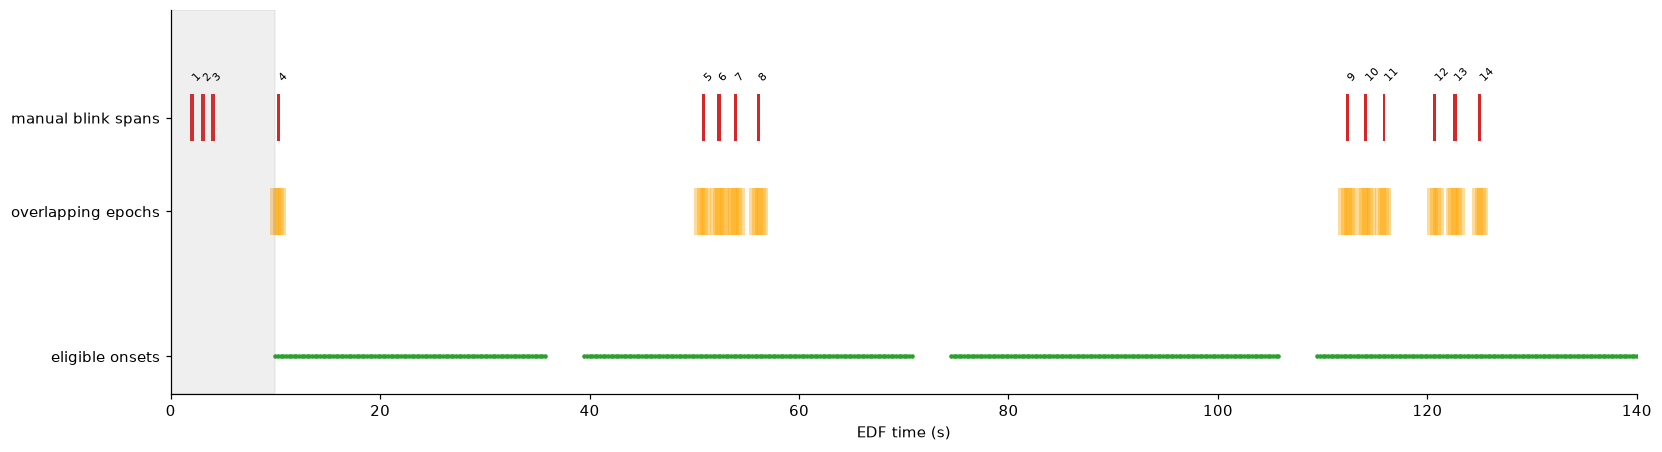

In [3]:
fig,ax=plt.subplots(figsize=(15,4),layout='constrained')
for i,r in intervals.iterrows():
    ax.broken_barh([(r.start_sec,r.end_sec-r.start_sec)],(1.15,.25),facecolors='tab:red')
    ax.text(r.start_sec,1.47,str(i+1),fontsize=7,rotation=45)
positive=events.manual_blink_overlap
for _,r in events[positive].iterrows():
    ax.broken_barh([(r.onset_seconds,record['epoch_samples']/record['sfreq'])],(.65,.25),facecolors='orange',alpha=.4)
ax.scatter(events.loc[events.evaluation_eligible,'onset_seconds'],np.zeros(events.evaluation_eligible.sum()),s=4,color='tab:green')
ax.axvspan(0,10,alpha=.12,color='gray')
ax.set(yticks=[0,.775,1.275],yticklabels=['eligible onsets','overlapping epochs','manual blink spans'],xlabel='EDF time (s)',ylim=(-.2,1.85),xlim=(0,140))
plt.show()

## 3. 原有阈值是否能排除这些眨眼？

把启动期拒绝与眨眼检出分开，仅比较非启动期、完整且无通道策略待定的 734 个 epoch。规则为任意 QC 通道 PTP **大于**上限即触发；这里单独检查高 PTP，因为低 PTP 与眨眼目标无关。

“标注外拒绝数”仍是未知：可能是尚未标出的眨眼，也可能是其他变化，不能称为假阳性。

,upper_uv,eligible_epochs,annotated_blink_epochs,detected_blink_epochs,missed_blink_epochs,annotated_epoch_detection_fraction,intervals_with_any_rejection,rejected_total,rejected_outside_annotation_unknown
0,75,734,48,40,8,0.833333,11,315,275
1,100,734,48,20,28,0.416667,7,162,142
2,125,734,48,2,46,0.041667,1,29,27
3,150,734,48,0,48,0.000000,0,5,5
4,200,734,48,0,48,0.000000,0,3,3
5,250,734,48,0,48,0.000000,0,0,0
6,350,734,48,0,48,0.000000,0,0,0


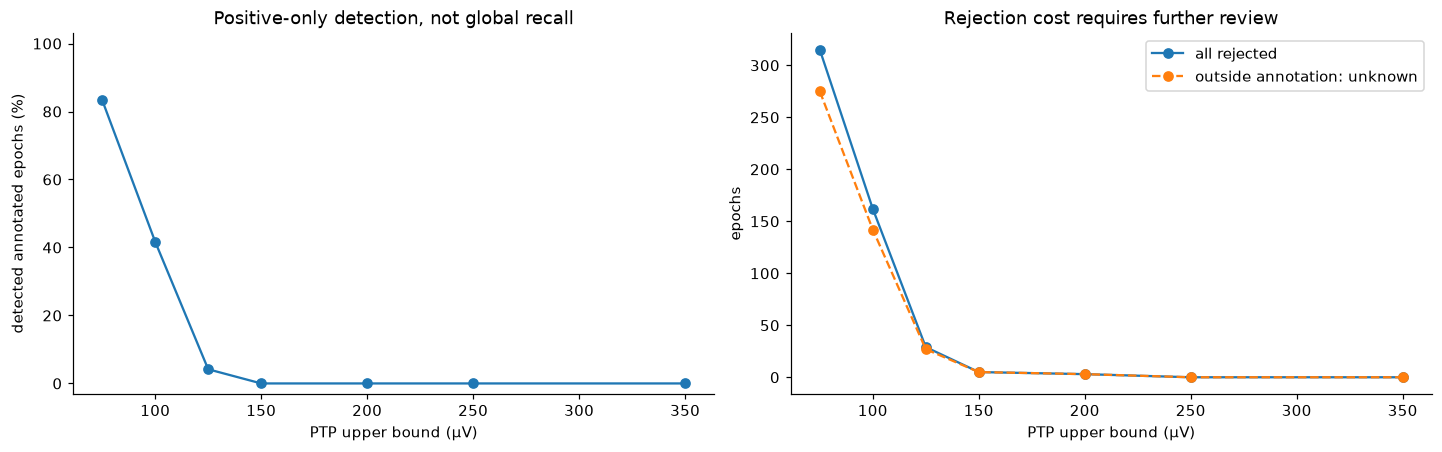

In [4]:
c=comparison[comparison.channel_group.eq('all16')].copy()
display(c[['upper_uv','eligible_epochs','annotated_blink_epochs','detected_blink_epochs','missed_blink_epochs',
           'annotated_epoch_detection_fraction','intervals_with_any_rejection','rejected_total','rejected_outside_annotation_unknown']])
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].plot(c.upper_uv,c.annotated_epoch_detection_fraction*100,'o-',label='annotated-overlap epochs')
axes[0].set(xlabel='PTP upper bound (µV)',ylabel='detected annotated epochs (%)',ylim=(-3,103),title='Positive-only detection, not global recall')
axes[1].plot(c.upper_uv,c.rejected_total,'o-',label='all rejected')
axes[1].plot(c.upper_uv,c.rejected_outside_annotation_unknown,'o--',label='outside annotation: unknown')
axes[1].set(xlabel='PTP upper bound (µV)',ylabel='epochs',title='Rejection cost requires further review')
axes[1].legend();plt.show()

**本次结果：**

| PTP 上限 | 检出的已标重叠 epoch | 至少命中一次的已标眨眼段 | 全部触发 epoch |
|---|---:|---:|---:|
| 250 µV | 0/48 | 0/11 | 0 |
| 150 µV | 0/48 | 0/11 | 5 |
| 125 µV | 2/48 | 1/11 | 29 |
| 100 µV | 20/48 | 7/11 | 162 |
| 75 µV | 40/48 | 11/11 | 315 |

因此原有阈值对这些眨眼明显太宽松。75 µV 虽命中了全部 11 段中的至少一个 epoch，仍漏掉 8 个重叠 epoch，并触发 315/734（42.9%）个 epoch；其中 275 个标注外触发尚不知对错。**不能据此把正式阈值直接改为 75 µV。**

以上数值是同一训练文件上的探索，不是独立验证性能；候选较低阈值应作为后续复核对象。

## 4. 为什么标了眨眼，PTP 却没有超过 150 µV？

下图按 epoch 画滤波后最大 PTP：橙色为已标眨眼相交，灰色为标注外未知。图中只做描述，不把灰色视为正常对照。

各标注区间再显示 F3/Fz/F4 的因果滤波波形，帮助判断已有标注边界和幅值；纵轴为 µV。眨眼不必超过固定 150 µV，且同一眨眼在不同 epoch 中截到的部分不同，PTP 也会不同。

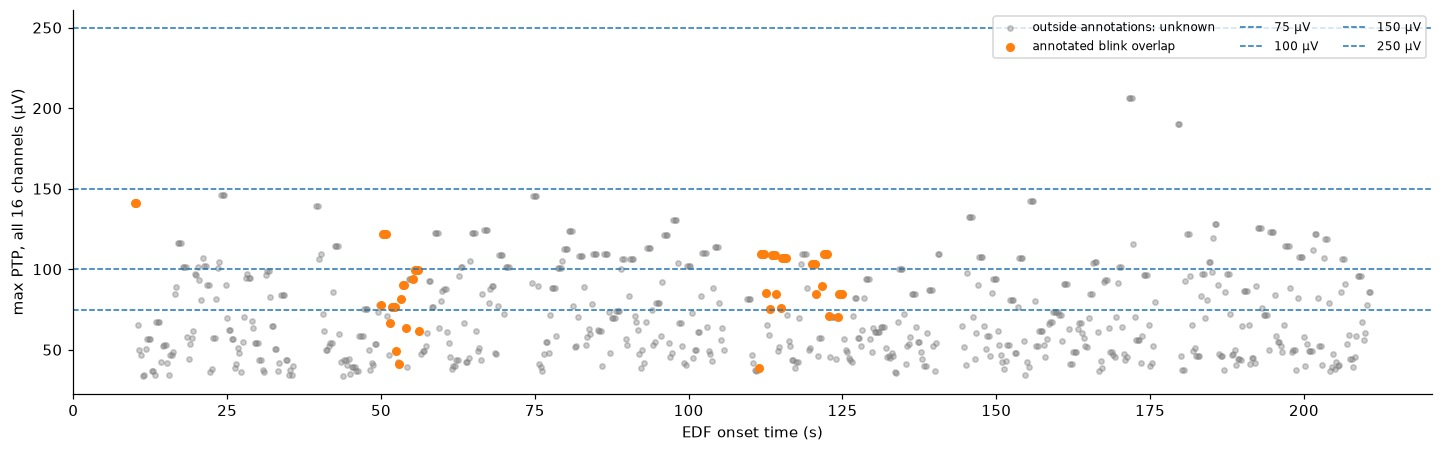

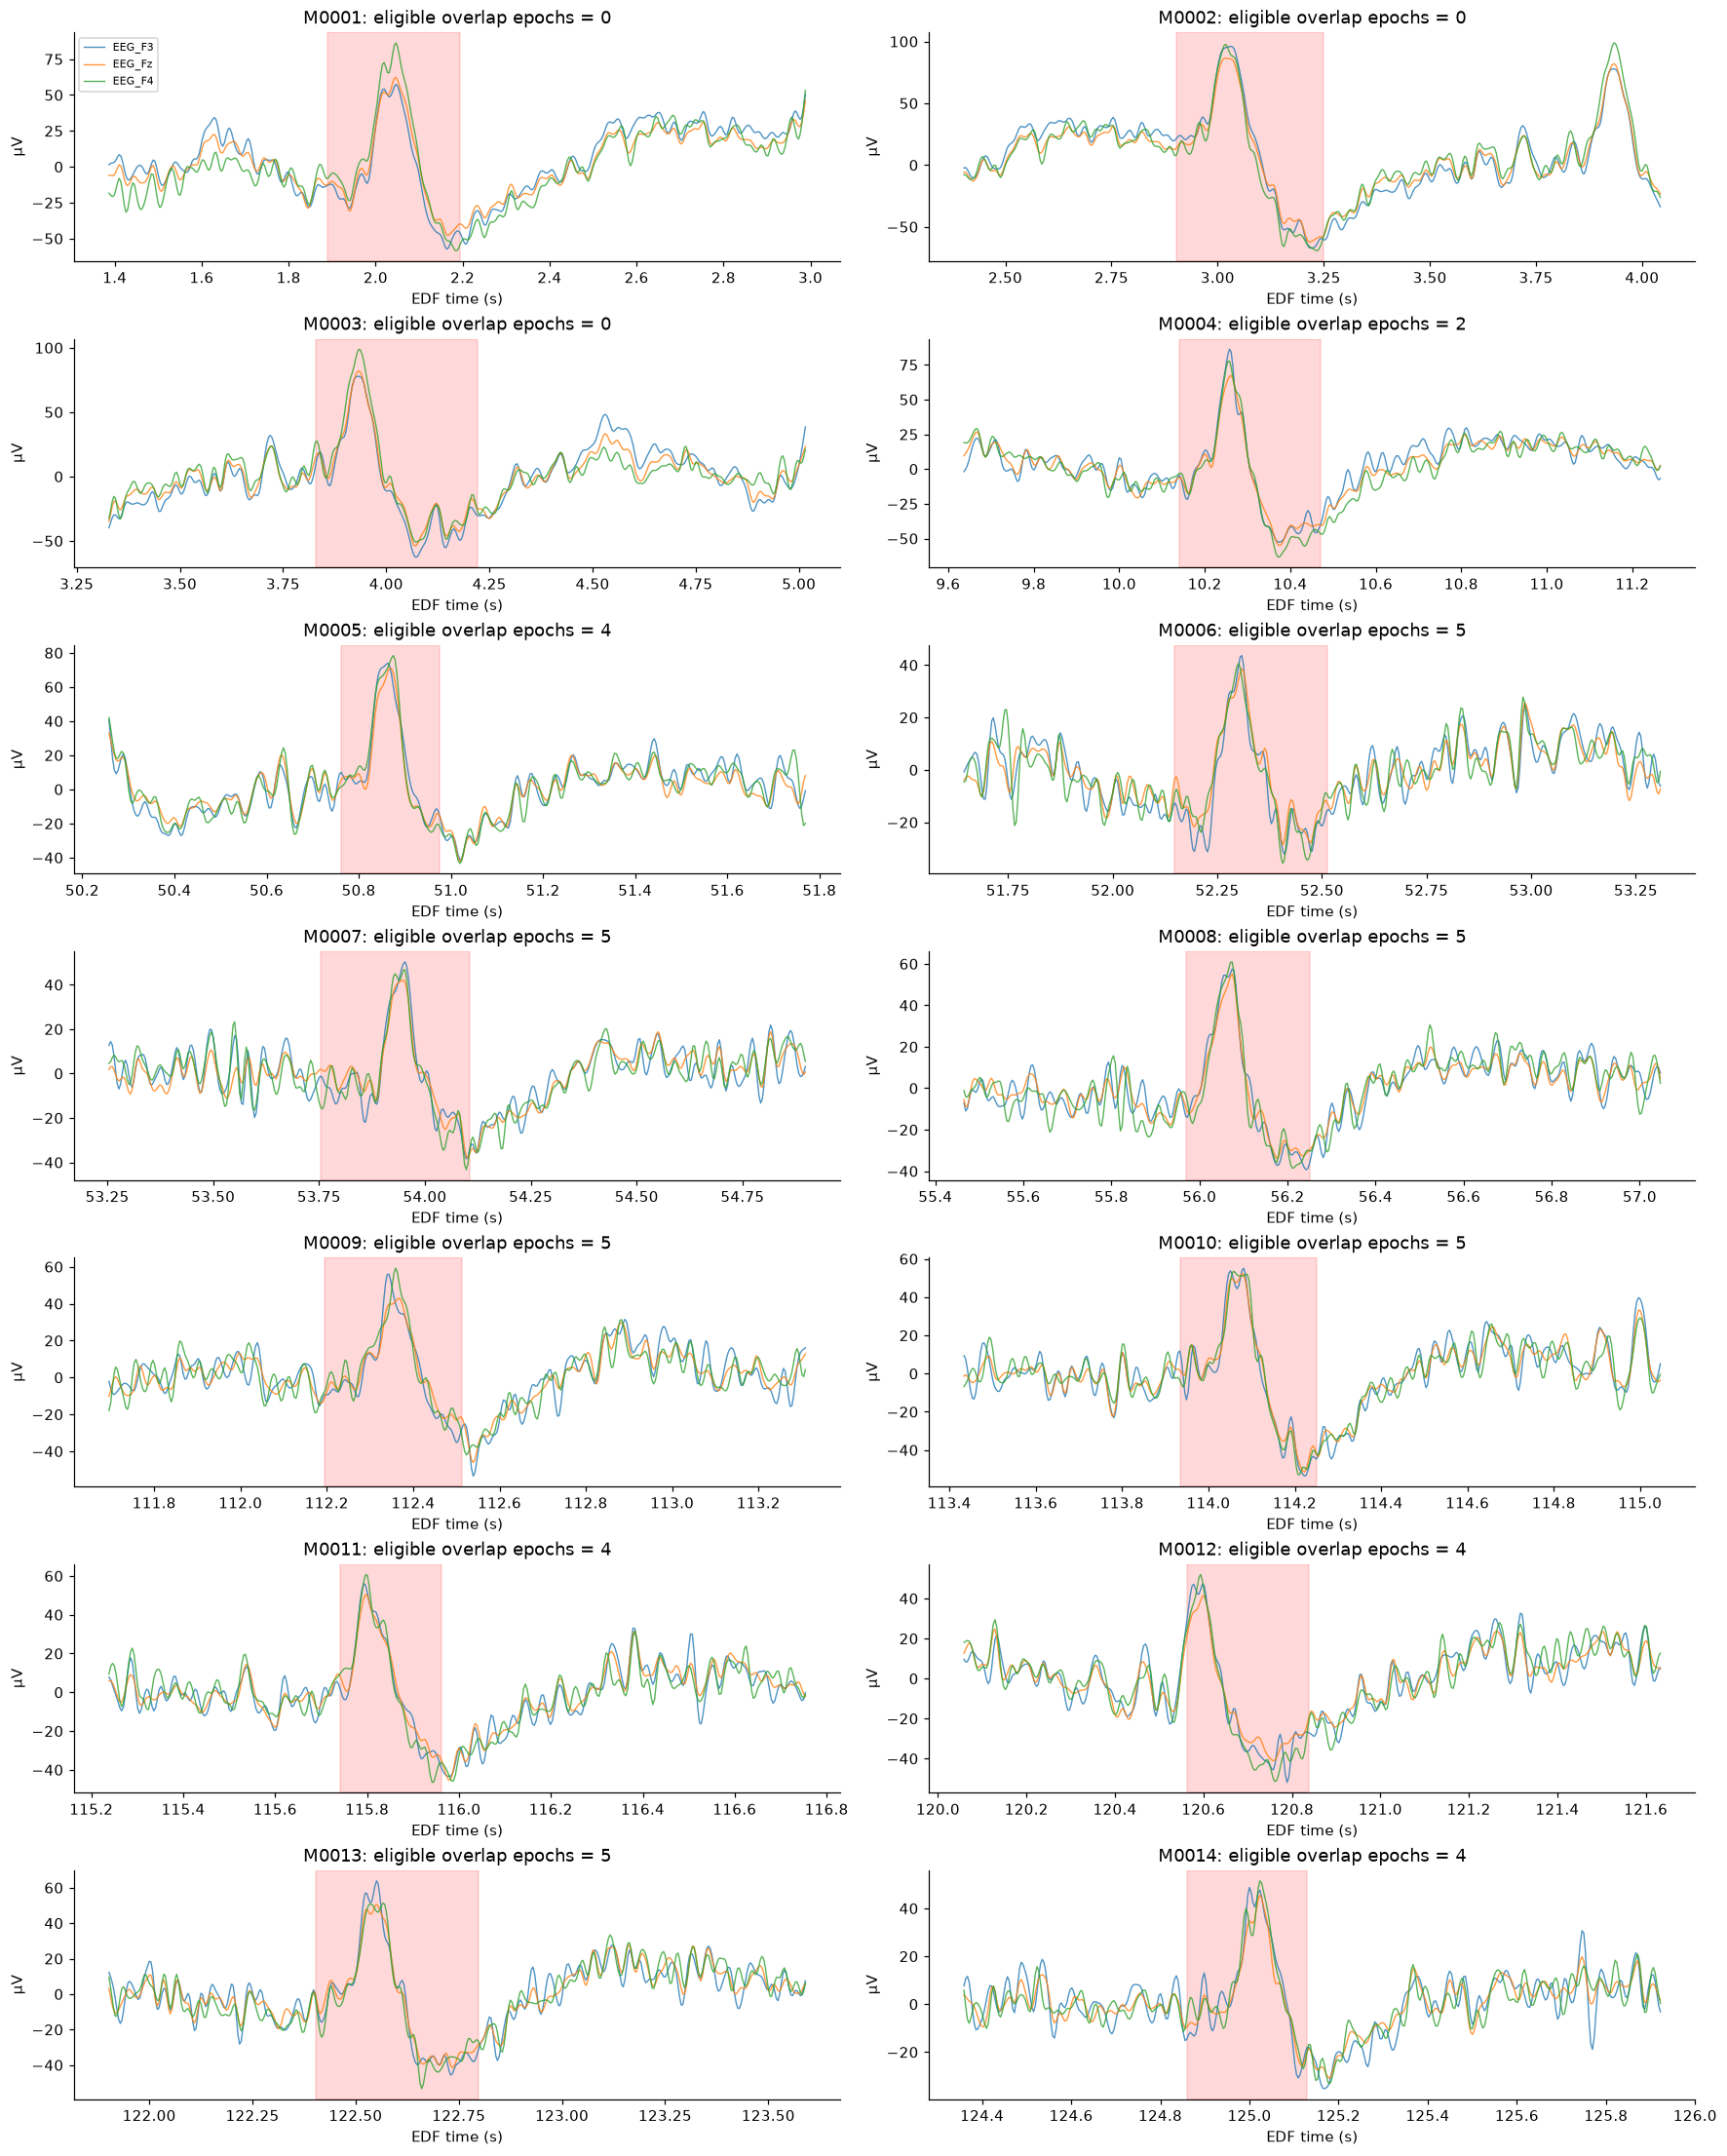

In [5]:
fig,ax=plt.subplots(figsize=(13,4),layout='constrained')
u=events.evaluation_eligible
ax.scatter(events.loc[u & ~positive,'onset_seconds'],events.loc[u & ~positive,'max_ptp_all_uv'],s=12,color='gray',alpha=.4,label='outside annotations: unknown')
ax.scatter(events.loc[u & positive,'onset_seconds'],events.loc[u & positive,'max_ptp_all_uv'],s=24,color='tab:orange',label='annotated blink overlap')
for h in [75,100,150,250]:ax.axhline(h,ls='--',lw=1,label=f'{h} µV')
ax.set(xlabel='EDF onset time (s)',ylabel='max PTP, all 16 channels (µV)');ax.legend(ncol=3,fontsize=8);plt.show()
with np.load(BASE/'continuous_causal_eeg.npz') as data:
    y=data['eeg_v'];channels=data['channels'].tolist();fs=float(data['sfreq'])
fig,axes=plt.subplots(7,2,figsize=(16,20),layout='constrained')
for ax,(_,r) in zip(axes.flat,intervals.iterrows()):
    a=max(0,int((r.start_sec-.5)*fs));b=min(y.shape[1],int((r.end_sec+.8)*fs))
    for ch in ['EEG_F3','EEG_Fz','EEG_F4']:
        ax.plot(np.arange(a,b)/fs,y[channels.index(ch),a:b]*1e6,label=ch,alpha=.8,lw=.9)
    ax.axvspan(r.start_sec,r.end_sec,color='red',alpha=.15)
    ax.set(title=f'{r.manual_id[-5:]}: eligible overlap epochs = {r.eligible_overlap_epochs}',xlabel='EDF time (s)',ylabel='µV')
axes.flat[0].legend(fontsize=7);plt.show()

## 5. 只看额部通道能改善吗？边界扩展会怎样？

额部三通道 F3/Fz/F4 是一个可检查的候选，不是已经确认的眨眼专用传感器，也不改变正式 QC 通道集合。下表比较全 16 通道与额部三通道的已标样本覆盖及拒绝数量。

人工标注来自原始波形，而 QC 使用因果滤波信号，滤波响应可能延伸到原始标注末尾以后。第二张表额外向后扩展 0.25/0.5 秒，只做敏感性分析，**不把扩展区间宣布为新的真实标注，也不移动事件**。

In [6]:
display(comparison[['channel_group','upper_uv','detected_blink_epochs','annotated_blink_epochs','rejected_total','rejected_outside_annotation_unknown']])
display(pd.read_csv(OUT/'padding_sensitivity.csv'))

,channel_group,upper_uv,detected_blink_epochs,annotated_blink_epochs,rejected_total,rejected_outside_annotation_unknown
0,all16,75,40,48,315,275
1,all16,100,20,48,162,142
2,all16,125,2,48,29,27
3,all16,150,0,48,5,5
4,all16,200,0,48,3,3
5,all16,250,0,48,0,0
6,all16,350,0,48,0,0
7,frontal3_exploratory,75,39,48,282,243
8,frontal3_exploratory,100,20,48,150,130
9,frontal3_exploratory,125,2,48,21,19


,post_annotation_padding_seconds,upper_uv,positive_epochs,detected,recall_on_provisional_spans
0,0.00,75,48,40,0.833333
1,0.00,100,48,20,0.416667
2,0.00,125,48,2,0.041667
3,0.00,150,48,0,0.000000
4,0.00,250,48,0,0.000000
5,0.25,75,59,40,0.677966
6,0.25,100,59,20,0.338983
7,0.25,125,59,2,0.033898
8,0.25,150,59,0,0.000000
9,0.25,250,59,0,0.000000


**如何判断：**PTP 是幅值指标，不具备眨眼来源特异性。即使额部限制减少标注外触发，也要靠完整检查的眨眼/非眨眼区间验证；不能仅凭正例覆盖就选出规则。若单一幅值阈值始终无法兼顾漏检和保留，再讨论增加眨眼形态或额部分布指标，当前不自动实施。

## 6. 还需要手动标注吗？优先标什么？

**需要补充，但先不要求标完整份或所有文件。**当前最缺的是“完整检查的连续区间”，而不只是更多明显眨眼正例。

建议先对两份训练 pilot 各完整复核 6 段、每段约 10 秒（合计约两分钟 EEG）。下面给出高 PTP、100 µV 附近、随机位置的优先片段。这是降低初轮复核工作量的起点，不是样本量充分的保证；特意富集的片段不能用于估计自然分布下的总体误删率。

逐段操作：

1. 在 notebook 04 打开对应 EDF，完整检查表中起止区间，标出**所有**眨眼，用 `MANUAL_blink`；不确定处标 `MANUAL_uncertain`，不要强判。
2. 显式记录这段已经完整检查。只有在已检查区间内、扣除眨眼和不确定片段后，才可构成已核查的无眨眼区域。眨眼范围要覆盖看到的完整波形过程，不要只标峰顶。
3. 如果看到了非眨眼的大幅变化，可以记录 `MANUAL_other_transient` 供核对，但不因此自动作为眨眼拒绝。NaN、缺失窗口等另归数据可用性检查。
4. 下一阶段用训练开发部分调候选规则，再用另外的训练文件/subject/session 独立验证；不要把重叠 epoch 随机拆开当独立样本。不同 calibration budget 仍须遵守其可见训练数据范围。

以下时间段尚未复核，review_status 保持 not_reviewed。建议表不会覆盖你的原始 annotation，也不会自动生成“正常”标签。

In [7]:
display(pd.read_csv(OUT/'suggested_review_intervals.csv'))
print('复核建议表：',OUT/'suggested_review_intervals.csv')

,site_inferred,edf_name,start_sec,end_sec,selection_reason,review_status,instruction
0,Duke,F_05_SE001_CBCol_Train02.edf,166.75,176.75,high PTP: blink or another transient?,not_reviewed,Review entire interval; annotate every blink a...
1,Duke,F_05_SE001_CBCol_Train02.edf,19.25,29.25,high PTP: blink or another transient?,not_reviewed,Review entire interval; annotate every blink a...
2,Duke,F_05_SE001_CBCol_Train02.edf,129.25,139.25,near exploratory 100uV cutoff,not_reviewed,Review entire interval; annotate every blink a...
3,Duke,F_05_SE001_CBCol_Train02.edf,84.00,94.00,near exploratory 100uV cutoff,not_reviewed,Review entire interval; annotate every blink a...
4,Duke,F_05_SE001_CBCol_Train02.edf,184.75,194.75,"random epoch-centered block, review full interval",not_reviewed,Review entire interval; annotate every blink a...
5,Duke,F_05_SE001_CBCol_Train02.edf,107.50,117.50,"random epoch-centered block, review full interval",not_reviewed,Review entire interval; annotate every blink a...
6,ETSU,F_03_SE001_CBCol_Train01.edf,92.75,102.75,high PTP: blink or another transient?,not_reviewed,Review entire interval; annotate every blink a...
7,ETSU,F_03_SE001_CBCol_Train01.edf,197.50,207.50,high PTP: blink or another transient?,not_reviewed,Review entire interval; annotate every blink a...
8,ETSU,F_03_SE001_CBCol_Train01.edf,169.75,179.75,near exploratory 100uV cutoff,not_reviewed,Review entire interval; annotate every blink a...
9,ETSU,F_03_SE001_CBCol_Train01.edf,123.00,133.00,near exploratory 100uV cutoff,not_reviewed,Review entire interval; annotate every blink a...


复核建议表： D:\BCI_project\bigp3bci-personalized-strategies\outputs\blink_validation\suggested_review_intervals.csv


## 7. 检查与本次决策

暂时保留原有正式配置，把它视为通用大幅异常的宽松候选；**尚不能宣称它满足“只排除眨眼”的目标**。已有人工标注已足以否定 150/250/350 µV 对本组眨眼的检出能力，但不足以选定更低最终阈值。等待完整检查区间与独立训练验证后再冻结眨眼规则。

分析产物在 `outputs/blink_validation`，重复计算用 `scripts/evaluate_manual_blinks.py`。正式 preprocessing 配置、原始 EDF、原始人工标注均未更改。有效性检查与眨眼伪迹判定继续分开保留。

In [8]:
assert len(intervals)==14
assert int((events.manual_blink_overlap & events.evaluation_eligible).sum())==48
assert comparison.loc[(comparison.channel_group=='all16') & (comparison.upper_uv>=150),'detected_blink_epochs'].eq(0).all()
assert comparison.precision.isna().all() and comparison.false_positive_rate.isna().all()
assert events.loc[~events.manual_blink_overlap,'reference_status'].eq('unknown_unreviewed_coverage').all()
print('PASS: 正例重叠、评估分母与未知区间处理检查通过；未计算无依据的误删率。')

PASS: 正例重叠、评估分母与未知区间处理检查通过；未计算无依据的误删率。
